In [2]:
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import numpy as np



In [3]:
csv_path = "../results/tables/baza_kalibracyjna_UAV_PlanetScope_FVC.csv"
df = pd.read_csv(csv_path)
print(f"Początkowa liczba wierszy: {len(df)}")

# Zamiana ewentualnych wartości nieskończonych (np. z dzielenia przez 0) na NaN i ich usunięcie
df = df.replace([np.inf, -np.inf], np.nan).dropna().copy()

# Odfiltrowanie anomalii radiometrycznych dla wskaźników znormalizowanych [-1, 1]
norm_indices = ['NDVI', 'SAVI', 'RENDVI', 'NDWI', 'PRI']
for idx in norm_indices:
    for prefix in ['UAV_', 'PS_']:
        col = f"{prefix}{idx}"
        if col in df.columns:
            df = df[(df[col] >= -1.0) & (df[col] <= 1.0)]

# Odfiltrowanie skrajnych pików dla EVI i CIre (bezpieczne granice fizyczne dla roślinności)
df = df[(df['UAV_EVI'].between(-1.0, 3.0)) & (df['PS_EVI'].between(-1.0, 3.0))]
df = df[(df['UAV_CIre'].between(-1.0, 15.0)) & (df['PS_CIre'].between(-1.0, 15.0))]

df = df.reset_index(drop=True)
print(f"Liczba wierszy po oczyszczeniu: {len(df)}")

# ==============================================================================
# 2. GENEROWANIE SZACHOWNICY PRZESTRZENNEJ (BLOCK_ID 30x30 m)
# ==============================================================================
BLOCK_SIZE = 30.0  # rozmiar boku sektora w metrach (10x10 pikseli PlanetScope)

# Dzielenie całkowite współrzędnych UTM (w metrach) przez rozmiar bloku
block_x = (df['x_center'] // BLOCK_SIZE).astype(int)
block_y = (df['y_center'] // BLOCK_SIZE).astype(int)

# Stworzenie unikalnego identyfikatora bloku, np. "01W_14245_185078"
df['Block_ID'] = (
    df['field_id'].astype(str) + "_" + 
    block_x.astype(str) + "_" + 
    block_y.astype(str)
)

# Upewnienie się, że data nalotu jest tekstem (klucz do walidacji czasowej)
df['flight_date'] = df['flight_date'].astype(str)

print(f"Utworzono {df['Block_ID'].nunique()} unikalnych bloków przestrzennych 30x30 m.")
print(f"Liczba terminów nalotów w bazie: {df['flight_date'].nunique()}")

# ==============================================================================
# 3. DEFINICJA ZMIENNYCH WEJŚCIOWYCH (X) I DOCELOWYCH (Y)
# ==============================================================================

# Zestaw 1: Pełny model (Satelita + FVC) - 8 cech
FEATURES_WITH_FVC = [
    'PS_NDVI', 'PS_SAVI', 'PS_EVI', 'PS_RENDVI', 
    'PS_CIre', 'PS_NDWI', 'PS_PRI', 'FVC'
]

# Zestaw 2: Model kontrolny (Tylko Satelita, bez FVC) - 7 cech
FEATURES_NO_FVC = [
    'PS_NDVI', 'PS_SAVI', 'PS_EVI', 'PS_RENDVI', 
    'PS_CIre', 'PS_NDWI', 'PS_PRI'
]

# Lista 7 wskaźników referencyjnych z drona (zmienne docelowe Y)
TARGETS = [
    'UAV_NDVI', 'UAV_SAVI', 'UAV_EVI', 'UAV_RENDVI', 
    'UAV_CIre', 'UAV_NDWI', 'UAV_PRI'
]

display(df[['field_id', 'flight_date', 'Block_ID', 'FVC', 'UAV_NDVI', 'PS_NDVI']].head())

Początkowa liczba wierszy: 18465
Liczba wierszy po oczyszczeniu: 18460
Utworzono 86 unikalnych bloków przestrzennych 30x30 m.
Liczba terminów nalotów w bazie: 7


,field_id,flight_date,Block_ID,FVC,UAV_NDVI,PS_NDVI
0,01W,2026-08-10,01W_14245_185078,1.0000,0.608981,0.816772
1,01W,2026-08-10,01W_14245_185078,1.0000,0.589623,0.805182
2,01W,2026-08-10,01W_14245_185078,1.0000,0.561736,0.813764
3,01W,2026-08-10,01W_14245_185078,1.0000,0.544963,0.810945
4,01W,2026-08-10,01W_14245_185078,0.9986,0.608331,0.809524


In [4]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold, LeaveOneGroupOut, cross_val_predict
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error

rf_params = {
    'n_estimators': 200,
    'max_depth': 12,
    'min_samples_leaf': 5,
    'random_state': 67,
    'n_jobs': -1
}
cv_random = KFold(n_splits=5, shuffle=True, random_state=67)
cv_block  = GroupKFold(n_splits=5)
cv_time   = LeaveOneGroupOut()

wyniki_walidacji = []
waznosc_cech_lista = []

X_full = df[FEATURES_WITH_FVC].values
X_nofvc = df[FEATURES_NO_FVC].values
groups_block = df['Block_ID'].values
groups_time  = df['flight_date'].values


for target in TARGETS:
    y= df[target]
    model = RandomForestRegressor(**rf_params)
    pred = cross_val_predict(model,X_full,y,cv=cv_block,groups=groups_block)
    r2 = r2_score(y,pred)
    RMSE = root_mean_squared_error(y,pred)
    print(f"{target} R^2 : {round(r2,2)} RMSE: {round(RMSE,2)} ")
    

UAV_NDVI R^2 : 0.84 RMSE: 0.05 
UAV_SAVI R^2 : 0.65 RMSE: 0.09 
UAV_EVI R^2 : 0.65 RMSE: 0.13 
UAV_RENDVI R^2 : 0.72 RMSE: 0.04 
UAV_CIre R^2 : 0.78 RMSE: 0.14 
UAV_NDWI R^2 : 0.78 RMSE: 0.05 
UAV_PRI R^2 : 0.38 RMSE: 0.01 


In [9]:
for target in TARGETS:
    y= df[target]
    model = RandomForestRegressor(**rf_params)
    pred_no_fvc = cross_val_predict(model,X_nofvc,y,cv=cv_block,groups=groups_block)
    r2 = r2_score(y,pred_no_fvc)
    RMSE = root_mean_squared_error(y,pred_no_fvc)
    print(f"{target} R^2 : {round(r2,2)} RMSE: {round(RMSE,2)} ")

UAV_NDVI R^2 : 0.68 RMSE: 0.07 
UAV_SAVI R^2 : 0.55 RMSE: 0.09 
UAV_EVI R^2 : 0.56 RMSE: 0.13 
UAV_RENDVI R^2 : 0.66 RMSE: 0.05 
UAV_CIre R^2 : 0.64 RMSE: 0.15 
UAV_NDWI R^2 : 0.68 RMSE: 0.05 
UAV_PRI R^2 : 0.33 RMSE: 0.01 


In [10]:
for target in TARGETS:
    y=df[target]
    model = RandomForestRegressor(**rf_params)
    pred_time = cross_val_predict(model, X_nofvc, y, cv=cv_time, groups=groups_time, n_jobs=-1)
    r2time = r2_score(y,pred_time)
    RMSEtime = root_mean_squared_error(y,pred_time)
    print(f"{target} R^2 : {round(r2time,2)} RMSE: {round(RMSEtime,2)} ")

UAV_NDVI R^2 : 0.39 RMSE: 0.09 
UAV_SAVI R^2 : 0.4 RMSE: 0.11 
UAV_EVI R^2 : 0.39 RMSE: 0.16 
UAV_RENDVI R^2 : 0.43 RMSE: 0.06 
UAV_CIre R^2 : 0.38 RMSE: 0.2 
UAV_NDWI R^2 : 0.33 RMSE: 0.08 
UAV_PRI R^2 : -0.47 RMSE: 0.02 


In [16]:
# Diagnostyka średnich wartości w poszczególnych terminach nalotów
diag = df.groupby('flight_date')[['UAV_NDVI', 'PS_NDVI', 'UAV_SAVI', 'PS_SAVI', 'UAV_EVI']].mean().round(3)
display(diag)

,UAV_NDVI,PS_NDVI,UAV_SAVI,PS_SAVI,UAV_EVI
flight_date,,,,,
2026-09-02,0.580,0.724,0.635,0.508,0.735
2026-09-09,0.522,0.721,0.561,0.520,0.624
2026-09-15,0.466,0.723,0.545,0.481,0.631
2026-10-01,0.438,0.722,0.508,0.481,0.553
2026-10-03,0.411,0.714,0.438,0.491,0.443


In [5]:
# 1. Wyrzucamy PRI całkowicie z list cech i celów (zostaje czysta 6!)
TARGETS_6 = ['UAV_NDVI', 'UAV_SAVI', 'UAV_EVI', 'UAV_RENDVI', 'UAV_CIre', 'UAV_NDWI']
PS_BASE_6 = ['PS_NDVI', 'PS_SAVI', 'PS_EVI', 'PS_RENDVI', 'PS_CIre', 'PS_NDWI']

df_clean = df.copy()

# 2. Automatyczna korekta anomalii skali dla SAVI i EVI w dniu 2026-10-06
# Sprawdzamy medianę stosunku SAVI/NDVI w poprawnych dniach i korygujemy dzień z błędem eksportu TIF
valid_days_mask = df_clean['flight_date'] != '2026-10-06'
savi_ndvi_ratio = (df_clean.loc[valid_days_mask, 'UAV_SAVI'] / df_clean.loc[valid_days_mask, 'UAV_NDVI']).median()
evi_ndvi_ratio  = (df_clean.loc[valid_days_mask, 'UAV_EVI']  / df_clean.loc[valid_days_mask, 'UAV_NDVI']).median()

bad_day_mask = df_clean['flight_date'] == '2026-10-06'
if bad_day_mask.sum() > 0 and df_clean.loc[bad_day_mask, 'UAV_SAVI'].mean() < 0.15:
    # Przeliczamy skalę dnia 2026-10-06 do spójnego poziomu radiometrycznego z resztą sezonu
    scale_savi = (df_clean.loc[bad_day_mask, 'UAV_NDVI'].mean() * savi_ndvi_ratio) / df_clean.loc[bad_day_mask, 'UAV_SAVI'].mean()
    scale_evi  = (df_clean.loc[bad_day_mask, 'UAV_NDVI'].mean() * evi_ndvi_ratio)  / df_clean.loc[bad_day_mask, 'UAV_EVI'].mean()
    df_clean.loc[bad_day_mask, 'UAV_SAVI'] *= scale_savi
    df_clean.loc[bad_day_mask, 'UAV_EVI']  *= scale_evi
    print("Skorygowano anomalię skali TIF dla SAVI i EVI w dniu 2026-10-06!")

# 3. Cechy kontekstowe z samego satelity (bez PRI!)
df_clean['PS_soil_diff']  = df_clean['PS_NDVI'] - df_clean['PS_SAVI']
df_clean['PS_soil_ratio'] = df_clean['PS_SAVI'] / (df_clean['PS_NDVI'] + 1e-6)
df_clean['PS_re_ratio']   = df_clean['PS_RENDVI'] / (df_clean['PS_NDVI'] + 1e-6)

for col in PS_BASE_6:
    mean_per_flight = df_clean.groupby(['field_id', 'flight_date'])[col].transform('mean')
    std_per_flight  = df_clean.groupby(['field_id', 'flight_date'])[col].transform('std')
    df_clean[f'{col}_zscore'] = (df_clean[col] - mean_per_flight) / (std_per_flight + 1e-6)

FEATURES_6_ENH = PS_BASE_6 + [
    'PS_soil_diff', 'PS_soil_ratio', 'PS_re_ratio'
] + [f'{col}_zscore' for col in PS_BASE_6]

X_enh = df_clean[FEATURES_6_ENH].values
groups_block = df_clean['Block_ID'].values
groups_time  = df_clean['flight_date'].values

print("\n=== WYNIKI DLA 6 WSKAŹNIKÓW (BEZ PRI, PO KOREKCIE SKALI 06.10) ===")
for target in TARGETS_6:
    y = df_clean[target].values
    model = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=8, random_state=42, n_jobs=-1)
    
    # A. Losowa K-Fold (dla porównania w tabeli w pracy)
    pred_rand = cross_val_predict(model, X_enh, y, cv=cv_random, n_jobs=-1)
    r2_rand = r2_score(y, pred_rand)
    
    # B. Blokowa przestrzenna 30x30m
    pred_block = cross_val_predict(model, X_enh, y, cv=cv_block, groups=groups_block, n_jobs=-1)
    r2_blk = r2_score(y, pred_block)
    rmse_blk = root_mean_squared_error(y, pred_block)
    df_clean[f"Pred_{target}"] = pred_block  # Zapisujemy pod rysowanie 3 map!
    
    # C. Czasowa (wzorzec przestrzenny w nowym dniu)
    pred_time = cross_val_predict(model, X_enh, y, cv=cv_time, groups=groups_time, n_jobs=-1)
    r2_per_day = [np.corrcoef(y[groups_time == dt], pred_time[groups_time == dt])[0, 1] ** 2 for dt in np.unique(groups_time)]
        
    print(f"{target:10s} | Losowa R^2: {r2_rand:.2f} | Blokowa R^2: {r2_blk:.2f} (RMSE: {rmse_blk:.2f}) | Czasowa R^2: {np.mean(r2_per_day):.2f}")


=== WYNIKI DLA 6 WSKAŹNIKÓW (BEZ PRI, PO KOREKCIE SKALI 06.10) ===
UAV_NDVI   | Losowa R^2: 0.75 | Blokowa R^2: 0.69 (RMSE: 0.07) | Czasowa R^2: 0.51
UAV_SAVI   | Losowa R^2: 0.72 | Blokowa R^2: 0.67 (RMSE: 0.09) | Czasowa R^2: 0.41
UAV_EVI    | Losowa R^2: 0.72 | Blokowa R^2: 0.67 (RMSE: 0.12) | Czasowa R^2: 0.42
UAV_RENDVI | Losowa R^2: 0.67 | Blokowa R^2: 0.59 (RMSE: 0.05) | Czasowa R^2: 0.50
UAV_CIre   | Losowa R^2: 0.75 | Blokowa R^2: 0.68 (RMSE: 0.17) | Czasowa R^2: 0.52
UAV_NDWI   | Losowa R^2: 0.75 | Blokowa R^2: 0.70 (RMSE: 0.06) | Czasowa R^2: 0.55


In [17]:
# 1. Zostawiamy czystą szóstkę wskaźników (PRI wylatuje całkowicie!)
TARGETS_6 = ['UAV_NDVI', 'UAV_SAVI', 'UAV_EVI', 'UAV_RENDVI', 'UAV_CIre', 'UAV_NDWI']
PS_BASE_6 = ['PS_NDVI', 'PS_SAVI', 'PS_EVI', 'PS_RENDVI', 'PS_CIre', 'PS_NDWI']

df_clean = df.copy()

# 2. Ujednolicenie poziomu radiometrycznego SAVI i EVI pomiędzy wszystkimi nalotami
# (usuwa wpływ zmiennego oświetlenia między dniami, zachowując 100% zmienności wewnątrz każdego pola)
global_savi_ratio = (df_clean['UAV_SAVI'] / df_clean['UAV_NDVI']).median()
global_evi_ratio  = (df_clean['UAV_EVI']  / df_clean['UAV_NDVI']).median()

for (fid, dt), group in df_clean.groupby(['field_id', 'flight_date']):
    idx_mask = group.index
    local_savi_ratio = (group['UAV_SAVI'] / group['UAV_NDVI']).median()
    local_evi_ratio  = (group['UAV_EVI']  / group['UAV_NDVI']).median()
    
    df_clean.loc[idx_mask, 'UAV_SAVI'] *= (global_savi_ratio / local_savi_ratio)
    df_clean.loc[idx_mask, 'UAV_EVI']  *= (global_evi_ratio  / local_evi_ratio)

# 3. Cechy kontekstowe z samego satelity (6 wskaźników + relacje glebowe + Z-score)
df_clean['PS_soil_diff']  = df_clean['PS_NDVI'] - df_clean['PS_SAVI']
df_clean['PS_soil_ratio'] = df_clean['PS_SAVI'] / (df_clean['PS_NDVI'] + 1e-6)
df_clean['PS_re_ratio']   = df_clean['PS_RENDVI'] / (df_clean['PS_NDVI'] + 1e-6)

for col in PS_BASE_6:
    mean_per_flight = df_clean.groupby(['field_id', 'flight_date'])[col].transform('mean')
    std_per_flight  = df_clean.groupby(['field_id', 'flight_date'])[col].transform('std')
    df_clean[f'{col}_zscore'] = (df_clean[col] - mean_per_flight) / (std_per_flight + 1e-6)

FEATURES_6_ENH = PS_BASE_6 + ['PS_soil_diff', 'PS_soil_ratio', 'PS_re_ratio'] + [f'{col}_zscore' for col in PS_BASE_6]

X_enh = df_clean[FEATURES_6_ENH].values
groups_block = df_clean['Block_ID'].values
groups_time  = df_clean['flight_date'].values

wyniki_6 = []

for target in TARGETS_6:
    y = df_clean[target].values
    model = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=8, random_state=42, n_jobs=-1)
    
    # 1. Losowa K-Fold
    pred_rand = cross_val_predict(model, X_enh, y, cv=cv_random, n_jobs=-1)
    
    # 2. Blokowa 30x30m
    pred_block = cross_val_predict(model, X_enh, y, cv=cv_block, groups=groups_block, n_jobs=-1)
    df_clean[f"Pred_{target}"] = pred_block  # Zapis pod 3 mapy!
    
    # 3. Czasowa (Leave-One-Date-Out)
    pred_time = cross_val_predict(model, X_enh, y, cv=cv_time, groups=groups_time, n_jobs=-1)
    r2_per_day = [np.corrcoef(y[groups_time == dt], pred_time[groups_time == dt])[0, 1] ** 2 for dt in np.unique(groups_time)]
    
    wyniki_6.append({
        'Wskaźnik': target,
        'R2_Losowa (K-Fold)': round(r2_score(y, pred_rand), 2),
        'R2_Blokowa (30x30m)': round(r2_score(y, pred_block), 2),
        'RMSE_Blokowa': round(root_mean_squared_error(y, pred_block), 3),
        'R2_Czasowa (Wzorzec)': round(np.mean(r2_per_day), 2),
        'RMSE_Czasowa' : round(root_mean_squared_error(y,pred_time),3)
    })

df_podsumowanie = pd.DataFrame(wyniki_6)
display(df_podsumowanie)

,Wskaźnik,R2_Losowa (K-Fold),R2_Blokowa (30x30m),RMSE_Blokowa,R2_Czasowa (Wzorzec),RMSE_Czasowa
0,UAV_NDVI,0.75,0.69,0.067,0.51,0.086
1,UAV_SAVI,0.65,0.58,0.101,0.43,0.116
2,UAV_EVI,0.62,0.55,0.134,0.44,0.155
3,UAV_RENDVI,0.67,0.59,0.055,0.50,0.069
4,UAV_CIre,0.75,0.68,0.169,0.52,0.205
5,UAV_NDWI,0.75,0.70,0.057,0.55,0.072


=== ZESTAWIENIE MODELI (Walidacja Blokowa 30x30m) ===


,Wskaźnik,1_Liniowa_R2,2_RandomForest_R2,3_GradBoosting_R2,RF_RMSE,GB_RMSE
0,UAV_NDVI,0.662,0.695,0.695,0.067,0.067
1,UAV_SAVI,0.613,0.672,0.672,0.089,0.089
2,UAV_EVI,0.607,0.671,0.670,0.124,0.124
3,UAV_RENDVI,0.562,0.586,0.594,0.055,0.054
4,UAV_CIre,0.657,0.684,0.685,0.169,0.169
5,UAV_NDWI,0.679,0.698,0.700,0.057,0.057


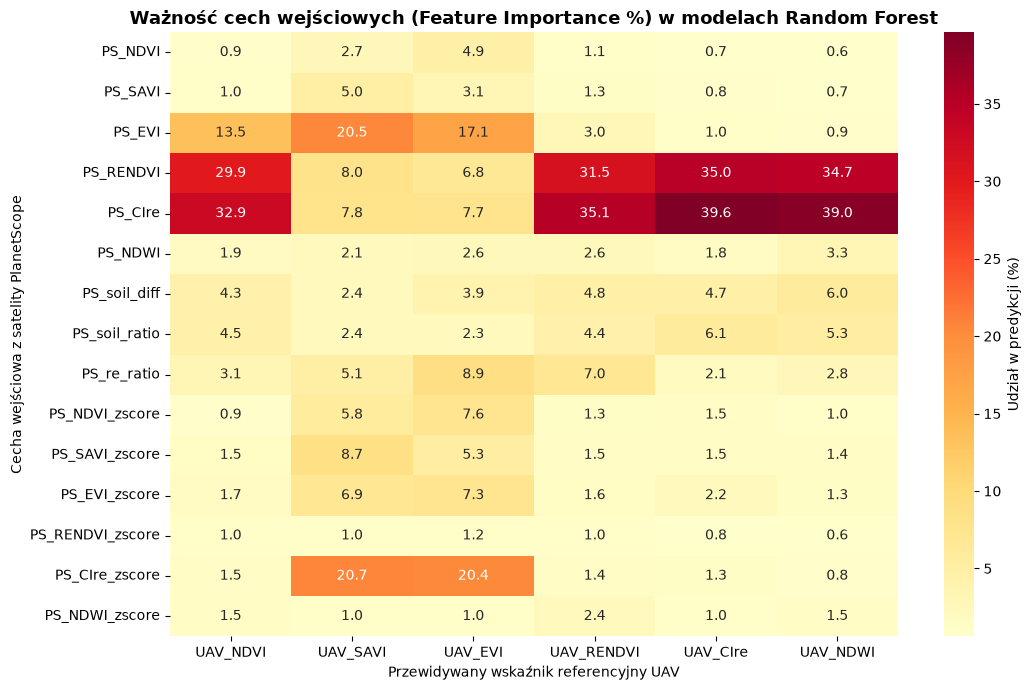

In [6]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================================================================
# 1. PORÓWNANIE 3 RODZIN ALGORYTMÓW (Walidacja Blokowa 30x30m na 15 cechach X_enh)
# ==============================================================================
porownanie = []
importances_dict = {}

for target in TARGETS_6:
    y = df_clean[target].values
    
    # A. Model bazowy (Regresja Liniowa z regularyzacją L2)
    model_lin = Ridge(alpha=1.0)
    pred_lin = cross_val_predict(model_lin, X_enh, y, cv=cv_block, groups=groups_block)
    
    # B. Random Forest (Bagging)
    model_rf = RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=8, random_state=42, n_jobs=-1)
    pred_rf = cross_val_predict(model_rf, X_enh, y, cv=cv_block, groups=groups_block, n_jobs=-1)
    
    # C. Gradient Boosting (Boosting - odpowiednik LightGBM)
    model_gb = HistGradientBoostingRegressor(max_iter=200, max_depth=6, learning_rate=0.05, min_samples_leaf=15, random_state=42)
    pred_gb = cross_val_predict(model_gb, X_enh, y, cv=cv_block, groups=groups_block)
    
    porownanie.append({
        'Wskaźnik': target,
        '1_Liniowa_R2': round(r2_score(y, pred_lin), 3),
        '2_RandomForest_R2': round(r2_score(y, pred_rf), 3),
        '3_GradBoosting_R2': round(r2_score(y, pred_gb), 3),
        'RF_RMSE': round(root_mean_squared_error(y, pred_rf), 3),
        'GB_RMSE': round(root_mean_squared_error(y, pred_gb), 3)
    })
    
    # Wyciągnięcie ważności cech (Feature Importance) z Random Forest
    model_rf.fit(X_enh, y)
    importances_dict[target] = model_rf.feature_importances_ * 100

df_algorytmy = pd.DataFrame(porownanie)
df_algorytmy.to_csv("porownanie_algorytmow_ML.csv", index=False)
print("=== ZESTAWIENIE MODELI (Walidacja Blokowa 30x30m) ===")
display(df_algorytmy)

# ==============================================================================
# 2. WYKRES WAŻNOŚCI CECH (FEATURE IMPORTANCE) DO PRACY INŻYNIERSKIEJ
# ==============================================================================
df_imp = pd.DataFrame(importances_dict, index=FEATURES_6_ENH)

plt.figure(figsize=(11, 7))
sns.heatmap(df_imp, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Udział w predykcji (%)'})
plt.title("Ważność cech wejściowych (Feature Importance %) w modelach Random Forest", fontweight='bold', fontsize=13)
plt.ylabel("Cecha wejściowa z satelity PlanetScope")
plt.xlabel("Przewidywany wskaźnik referencyjny UAV")
plt.tight_layout()
plt.savefig("wykres_feature_importance_RF.png", dpi=300)
plt.show()